# Demo: orquestador multi-agente del Edificio Riesco 6540

En este notebook muestro cómo el supervisor reparte el trabajo entre el **investigador** y el **analista** con cuatro tipos de pregunta:

1. Una que necesita **buscar y calcular** (mudanzas).
2. Otra con cálculo, pero en un tema distinto (multas por reincidencia).
3. Una que **solo necesita buscar**, donde el supervisor no debería llamar al analista.
4. Una cuyo dato **no está en el reglamento**, donde la respuesta debería decirlo con honestidad.

Al final hay una sección con las validaciones que no dependen del LLM.

> Requiere el archivo `.env` con las claves de OpenAI y Pinecone (ver el README). Cada pregunta hace entre 4 y 8 llamadas a OpenAI.

In [1]:
from IPython.display import Image, display

import config
from main import configurar_logging, ejecutar

configurar_logging()
config.validar_credenciales()


def demo(pregunta: str) -> None:
    """Ejecuta el grafo mostrando cada delegación y luego la respuesta final."""
    print(f"❓ Pregunta: {pregunta}\n")
    respuesta = ejecutar(pregunta)
    print("=" * 70)
    print("✅ RESPUESTA FINAL\n")
    print(respuesta)

## El grafo

El supervisor es el único nodo con aristas condicionales (punteadas). Los especialistas siempre le devuelven el control.

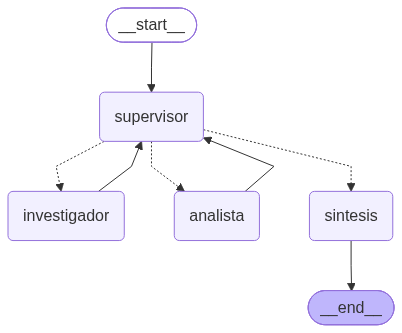

In [2]:
display(Image("diagrama.png"))

## Caso 1: buscar y calcular

La pregunta no trae los horarios, así que el supervisor tiene que mandar primero al investigador. Después, como el total semanal **no aparece literalmente** en el reglamento, debería mandar el cálculo al analista.

**Esperado:** `investigador → analista → FINISH`, con 57.5 horas.

In [3]:
demo("¿Cuántas horas a la semana se permiten mudanzas en el edificio?")

❓ Pregunta: ¿Cuántas horas a la semana se permiten mudanzas en el edificio?

🧭 supervisor → investigador
   razón: Paso 1 del orden de trabajo: falta dato del reglamento para responder la pregunta.
   instrucción: Busca en el reglamento de copropiedad del Edificio Riesco 6540 la norma que indique el horario permitido para realizar mudanzas, específicamente cuántas horas a la semana están autorizadas para esta actividad. Cita la fuente con archivo y sección.

🔹 investigador:
   El horario permitido para realizar mudanzas en el Edificio Riesco 6540 es:
   - Lunes a viernes: entre las 07:00 y las 17:30 horas.
   - Sábados: entre las 09:00 y las 14:00 horas.
   - Domingos y días festivos: está estrictamente prohibida la realización de mudanzas.

   El reglamento no especifica un límite en horas semanales autorizadas para mudanzas, solo establece los horarios diarios permitidos.

   Fuente: obras_mudanzas.txt, Sección "Protocolo de Mudanzas y Carga en Ascensores".

🧭 supervisor → analista
 

## Caso 2: otro cálculo, otro tema

Multas: el reglamento dice que la multa es de 2 UTM y que, si se reincide dentro de seis meses, se duplica. El total no está escrito en ninguna parte.

**Esperado:** `investigador → analista → FINISH`, con 6 UTM (2 + 4).

In [4]:
demo("Si un vecino es multado por fumar en el pasillo y reincide a los 3 meses, ¿cuántas UTM paga en total?")

❓ Pregunta: Si un vecino es multado por fumar en el pasillo y reincide a los 3 meses, ¿cuántas UTM paga en total?

🧭 supervisor → investigador
   razón: Paso 1 del orden de trabajo: falta un dato del reglamento para responder la pregunta.
   instrucción: Busca en el reglamento las normas relacionadas con multas por fumar en el pasillo, incluyendo el monto en UTM de la multa y si hay alguna disposición sobre multas por reincidencia, especialmente si se menciona un plazo de 3 meses.

🔹 investigador:
   Las multas por fumar en el pasillo, que está prohibido en todas las áreas comunes, son de dos Unidades Tributarias Mensuales (UTM). Si se comete la misma infracción dentro de los seis meses posteriores a la resolución sancionatoria, la multa se duplica a cuatro UTM. No se menciona un plazo de 3 meses para multas por reincidencia, sino de seis meses.

   Fuente: Sección "Procedimiento Sancionatorio y Régimen de Multas" y "Normas de Convivencia, Emisiones de Humo y Ruido" del Reglamento de C

## Caso 3: solo búsqueda

Aquí no hay nada que calcular. Lo interesante es ver que el supervisor **se salta al analista** y termina apenas tiene la información con su fuente.

**Esperado:** `investigador → FINISH`.

In [10]:
demo("¿Puedo tener mascotas en el edificio? ¿Hay alguna regla que deba cumplir?")

❓ Pregunta: ¿Puedo tener mascotas en el edificio? ¿Hay alguna regla que deba cumplir?

🧭 supervisor → investigador
   razón: Paso 1 del orden de trabajo: falta un dato del reglamento para responder la pregunta.
   instrucción: Busca en el reglamento de copropiedad del Edificio Riesco 6540 si está permitido tener mascotas en el edificio y si existen reglas específicas que deban cumplirse. Cita la fuente (archivo y sección).

🔹 investigador:
   Está permitido tener mascotas en el edificio durante la etapa inicial mientras se constituye el Comité de Administración. Luego, este comité junto con la asamblea fijará las reglas definitivas. Mientras tanto, hay dos obligaciones mínimas: 
   1) Prohibición de circulación libre o sin sujeción (los animales deben ir con collar o correa en espacios comunes).
   2) Obligación inmediata de aseo y saneamiento si las mascotas ensucian espacios comunes.

   El incumplimiento de estas normas mínimas puede ser sancionado con multas según el régimen genera

## Caso 4: un dato que no está en el reglamento

El reglamento dice que las visitas a la piscina pagan una tarifa fijada por el Comité de Administración, pero **no dice cuánto es**. Este caso sirve para ver que nadie inventa el monto.

**Esperado:** el investigador indica que el dato no está, el supervisor puede pedir un segundo intento con otros términos, y la respuesta final lo informa con honestidad.

In [11]:
demo("¿Cuánto cuesta llevar una visita a la piscina del edificio?")

❓ Pregunta: ¿Cuánto cuesta llevar una visita a la piscina del edificio?

🧭 supervisor → investigador
   razón: Paso 1 del orden de trabajo: falta un dato del reglamento para responder la pregunta.
   instrucción: Busca en el reglamento de copropiedad del Edificio Riesco 6540 la norma que indique el costo o tarifa para llevar una visita a la piscina del edificio. Cita la fuente exacta (archivo y sección).

🔹 investigador:
   El reglamento indica que para llevar una visita a la piscina del edificio, el copropietario debe solicitar permiso por escrito al Administrador, quien puede autorizar o denegar el ingreso y fija la tarifa especial que debe pagarse anticipadamente para estos fines. Sin embargo, no se especifica el monto exacto de la tarifa en el reglamento.

   Fuente: espacios_comunes.txt, Sección: Régimen Integral de la Piscina del Condominio.

🧭 supervisor → investigador
   razón: El investigador indicó que el reglamento menciona que se debe pagar una tarifa especial para visitas 

## Validaciones que no dependen del LLM

Estas celdas no llaman a OpenAI: muestran las partes deterministas del sistema.

### La calculadora segura

Solo acepta números y operadores aritméticos. Cualquier otra cosa se rechaza con un mensaje, sin ejecutarse.

In [7]:
from agents.tools import calculadora

for expresion in ["5 * (17.5 - 7) + (14 - 9)", "2 + 2 * 2", "__import__('os').getcwd()", "9 ** 9 ** 9", "1 / 0"]:
    print(f"{expresion!r:32} → {calculadora.invoke(expresion)}")

'5 * (17.5 - 7) + (14 - 9)'      → 5 * (17.5 - 7) + (14 - 9) = 57.5
'2 + 2 * 2'                      → 2 + 2 * 2 = 6
"__import__('os').getcwd()"      → Error al calcular '__import__('os').getcwd()': operación no permitida: Call
'9 ** 9 ** 9'                    → Error al calcular '9 ** 9 ** 9': exponente mayor a 100
'1 / 0'                          → Error al calcular '1 / 0': división por cero.


### La validación de cifras en la síntesis

Cada número de la respuesta final tiene que venir de la pregunta o de algún aporte. Aquí se compara una respuesta que calcula por su cuenta con una que no.

In [8]:
from agents.supervisor import _numeros_inventados

contexto = (
    "Pregunta: ¿Cuántas horas a la semana se permiten mudanzas?\n"
    "Aporte del investigador: lunes a viernes de 07:00 a 17:30; sábados de 09:00 a 14:00."
)
inventa = "Se permiten 57.5 horas a la semana (10.5 × 5 + 5)."
honesta = "Lunes a viernes de 07:00 a 17:30 y sábados de 09:00 a 14:00. No se alcanzó a calcular el total semanal."

print("Respuesta que inventa →", sorted(_numeros_inventados(inventa, contexto)))
print("Respuesta honesta     →", sorted(_numeros_inventados(honesta, contexto)) or "sin números inventados")

Respuesta que inventa → ['10.5', '5', '57.5']
Respuesta honesta     → sin números inventados


### El límite de pasos

Si se alcanza `MAX_PASOS`, el supervisor termina sin consultar al LLM. Es la protección contra el "supervisor infinito".

In [9]:
from agents.supervisor import nodo_supervisor
from main import estado_inicial

estado = estado_inicial("Pregunta cualquiera")
estado["pasos"] = config.MAX_PASOS
print(nodo_supervisor(estado))

{'next_agent': 'FINISH', 'instruccion': '', 'razon': 'Se alcanzó el límite de 6 pasos.', 'task_completed': True}
